# LED-pulsed waveform simulation

Generate independent 5 s I/Q chunks with LED timing synchronized to the DAQ:

- First LED rising edge at **50 ms**, then **50 µs ON + 300 ms OFF** (300.05 ms period).
- Each pulse produces a Poisson-distributed number of **tunneling events**, with a tunable mean. Excitation is uniform during ON; delays reuse the existing Gaussian-plus-exponential profile (μ = 1.2 ms, σ = 0.4 ms, τ = 3.7 ms), conditioned on nonnegative delays.
- Offset charge is redrawn uniformly from **[−0.5, 0.5)** at each rising edge and at independent random jumps averaging **one per minute**. It stays fixed between resets.
- A **20 Hz** quiescent tunneling contribution remains active throughout ON and OFF, independent of LED events.

Chunks restart independently, including their initial charge and parity; their pulse times have the same DAQ alignment. A charge reset alone does **not** flip parity. Run this notebook with the `straxion` Python environment.

In [1]:
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt

from qpd import (
    QPD, ResonatorConfig, VNASimulator, WhiteGaussianNoise,
    LEDPulseModel, led_count_sweep,
)

plt.style.use(QPD._style_path)

## Configure one chunk

`expected_n_qp` is the Poisson **mean tunneling count per pulse**, not a physical quasiparticle population. Set it to zero for a control run: charge resets and quiescent tunneling still occur. All timing parameters below are in seconds.

In [2]:
DURATION = 5.0
SAMPLE_RATE = 100_000.0
MEAN_TUNNELS_PER_PULSE = 10.0
SEED = 0

led = LEDPulseModel(
    on_time=50e-6,
    off_time=300e-3,
    first_pulse_time=50e-3,
    expected_n_qp=MEAN_TUNNELS_PER_PULSE,
    charge_jump_rate_hz=1.0 / 60.0,
)

qpd = QPD(e_j_hz=6.95e9, e_c_hz=0.695e9)
qpd.coupling_g_hz = 40e6
resonator = ResonatorConfig(
    f_r=6.936e9, q_i=1e5, q_c_abs=1.2e5,
    phi=0.03, a=0.5, alpha=0.4, tau=50e-9,
)
# Probe near the dressed even-parity line at a reference offset charge.
_, chi_reference = qpd.compute_dispersive_matrix(
    0.25, coupling_g_hz=qpd.coupling_g_hz,
    readout_freq_hz=resonator.f_r, num_levels=2, parity="even",
)
f_drive = resonator.f_r + chi_reference[0] + 1e3
simulator = VNASimulator(
    qpd=qpd, resonator=resonator, f_drive=f_drive,
    sample_rate=SAMPLE_RATE,
    gamma_even_to_odd=20.0, gamma_odd_to_even=20.0,
    noise=WhiteGaussianNoise(sigma=2e-4),
    led_pulsing=led,
)
result = simulator.simulate(duration=DURATION, seed=SEED)
truth = result.led

# Exact event truth retains tunnels too close together to resolve on the sample grid.
led_events = truth.event_times
led_events_observed = led_events[
    (led_events > result.t[0]) & (led_events <= result.t[-1])
]
background_events = result.flip_times[
    ~np.isin(result.flip_times, led_events_observed)
]
random_reset_times = truth.charge_reset_times[~truth.charge_reset_is_led]
pulse_counts = np.array([burst.n_qp for burst in truth.bursts])

print(f"Samples: {result.t.size:,}; LED pulses: {len(truth.pulse_times)}")
print(f"First pulse: {truth.pulse_times[0] * 1e3:.2f} ms; period: {led.period * 1e3:.2f} ms")
print(f"Configured mean: {led.expected_n_qp:g}; realised mean: {pulse_counts.mean():.2f} tunnels/pulse")
print(f"Recorded tunnels: {len(led_events_observed)} LED + {len(background_events)} quiescent")
print(f"Spontaneous charge resets: {len(random_reset_times)}")

Samples: 500,000; LED pulses: 17
First pulse: 50.00 ms; period: 300.05 ms
Configured mean: 10; realised mean: 11.24 tunnels/pulse
Recorded tunnels: 191 LED + 99 quiescent
Spontaneous charge resets: 1


## Full chunk

The I/Q traces below are thinned only for display. Charge reset vertices are plotted directly from truth so even short charge plateaus remain visible. Shaded intervals mark LED ON; rising-edge lines make the 50 µs pulses visible on this 5 s scale. Most chunks contain no spontaneous charge jump: the expected number is only 5/60.

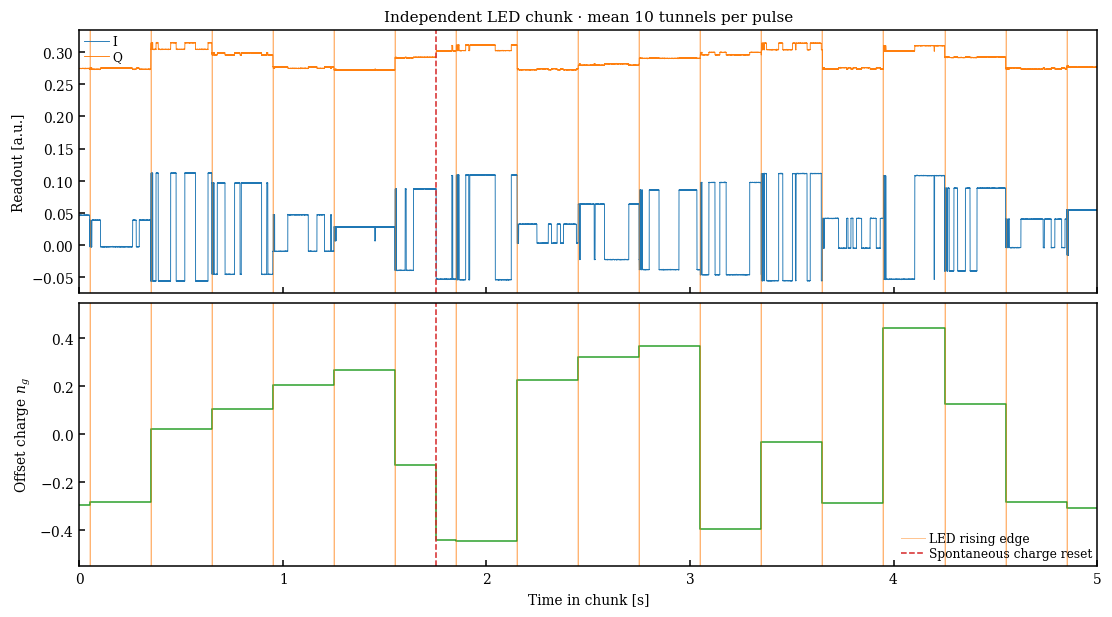

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, constrained_layout=True)
stride = max(1, result.t.size // 20_000)
axes[0].plot(result.t[::stride], result.i[::stride], lw=0.6, label="I")
axes[0].plot(result.t[::stride], result.q[::stride], lw=0.6, label="Q")
axes[0].set_ylabel("Readout [a.u.]")
axes[0].legend(loc="best")

charge_t = np.r_[0.0, truth.charge_reset_times, DURATION]
charge_values = np.r_[truth.initial_n_g, truth.charge_reset_values,
                      truth.charge_reset_values[-1] if truth.charge_reset_values.size else truth.initial_n_g]
axes[1].step(charge_t, charge_values, where="post", color="C2", lw=1)
axes[1].set_ylabel(r"Offset charge $n_g$")
axes[1].set_ylim(-0.55, 0.55)
axes[1].set_xlabel("Time in chunk [s]")

for ax in axes:
    for index, (start, end) in enumerate(zip(truth.pulse_times, truth.pulse_end_times)):
        ax.axvspan(start, end, color="C1", alpha=0.3)
        ax.axvline(start, color="C1", lw=0.65, alpha=0.45,
                   label="LED rising edge" if index == 0 else None)
    for index, reset in enumerate(random_reset_times):
        ax.axvline(reset, color="C3", ls="--", lw=1,
                   label="Spontaneous charge reset" if index == 0 else None)
    ax.set_xlim(0, DURATION)
axes[1].legend(loc="best")
axes[0].set_title(f"Independent LED chunk · mean {led.expected_n_qp:g} tunnels per pulse")
plt.show()

## Resolve the first pulse

Parity is sampled at 100 kHz (10 µs between samples). The event raster shows exact tunneling times; multiple tunnels within one sample can cancel in the sampled parity. Orange shading indicates illumination, not the entire tunneling burst. The charge reset at the LED rising edge is separate from the later tunneling events.

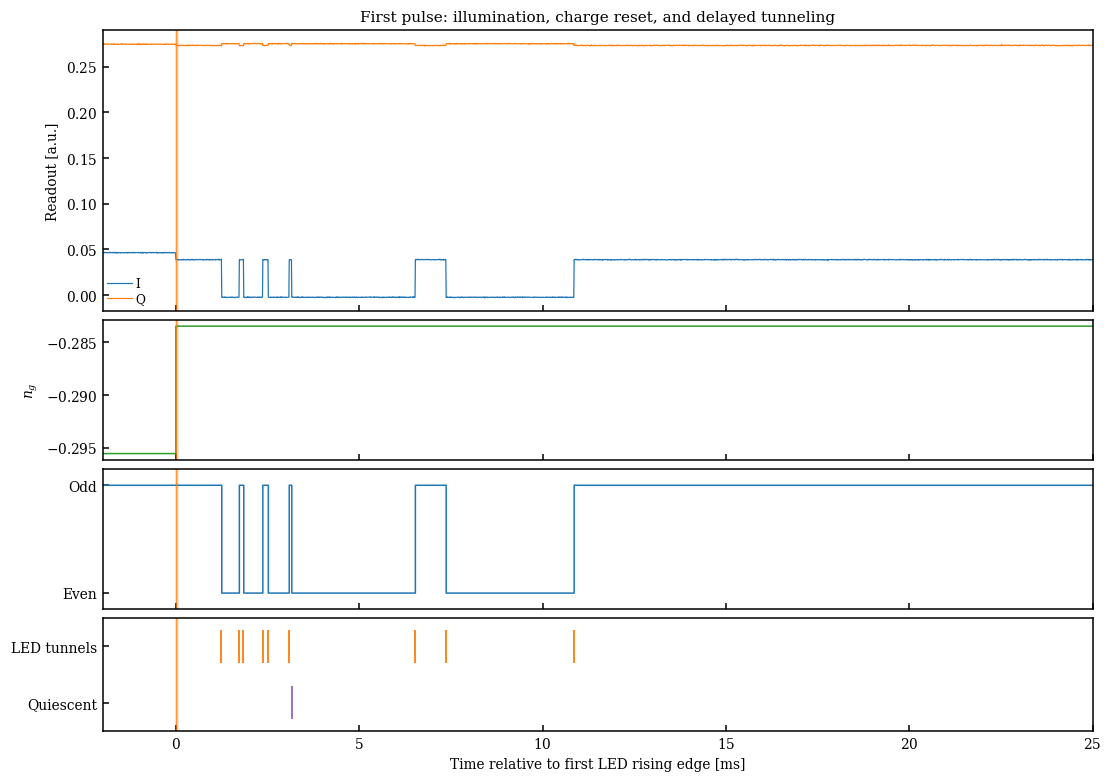

In [4]:
pulse_start = truth.pulse_times[0]
window_start, window_end = pulse_start - 2e-3, pulse_start + 25e-3
zoom = (result.t >= window_start) & (result.t <= window_end)
relative_ms = (result.t[zoom] - pulse_start) * 1e3

fig, axes = plt.subplots(
    4, 1, figsize=(10, 7), sharex=True, constrained_layout=True,
    gridspec_kw={"height_ratios": [2, 1, 1, 0.8]},
)
axes[0].plot(relative_ms, result.i[zoom], lw=0.8, label="I")
axes[0].plot(relative_ms, result.q[zoom], lw=0.8, label="Q")
axes[0].set_ylabel("Readout [a.u.]")
axes[0].legend(loc="best")
axes[1].step(relative_ms, result.n_g[zoom], where="post", color="C2")
axes[1].set_ylabel(r"$n_g$")
axes[2].step(relative_ms, result.parity[zoom], where="post", color="C0", lw=1)
axes[2].set_yticks([0, 1], labels=["Even", "Odd"])
axes[2].set_ylim(-0.15, 1.15)

for events, level, color in [(led_events_observed, 1, "C1"),
                              (background_events, 0, "C4")]:
    visible = events[(events >= window_start) & (events <= window_end)]
    axes[3].vlines((visible - pulse_start) * 1e3, level - 0.3, level + 0.3,
                   color=color, lw=1.2)
axes[3].set_yticks([0, 1], labels=["Quiescent", "LED tunnels"])
axes[3].set_ylim(-0.5, 1.5)
axes[3].set_xlabel("Time relative to first LED rising edge [ms]")
for ax in axes:
    ax.axvspan(0, led.on_time * 1e3, color="C1", alpha=0.25)
    ax.axvline(0, color="C1", lw=0.8, alpha=0.7)
    ax.set_xlim((window_start - pulse_start) * 1e3,
                (window_end - pulse_start) * 1e3)
axes[0].set_title("First pulse: illumination, charge reset, and delayed tunneling")
plt.show()

## Logarithmic count settings and independent chunks

Zero is a separate control setting. `led_count_sweep(points_per_decade=10)` returns zero plus 31 logarithmically spaced means from 1 to 1000. Means need not be integers; the realized Poisson counts are integers. Each setting stays fixed across all pulses in its chunk.

The optional loop below runs just five representative settings and retains a compact summary. Set `RUN_SWEEP = True` to execute it, or replace `selected_means` with `count_settings` for the full sweep. Each call to `simulate` starts a fresh chunk; distinct seeds vary its charge and tunneling realizations while preserving LED phase. Reusing a seed reproduces a chunk.

In [5]:
count_settings = led_count_sweep(points_per_decade=10)
print("Poisson means:", np.array2string(count_settings, precision=3))

RUN_SWEEP = False
selected_means = count_settings[[0, 1, 11, 21, 31]]  # 0, 1, 10, 100, 1000
sweep_summary = []
if RUN_SWEEP:
    print("mean/pulse    realised/pulse    observed flips")
    for index, mean in enumerate(selected_means):
        sweep_simulator = replace(
            simulator, led_pulsing=replace(led, expected_n_qp=float(mean))
        )
        chunk = sweep_simulator.simulate(duration=DURATION, seed=100 + index)
        assert np.array_equal(chunk.led.pulse_times, truth.pulse_times)
        realised_mean = np.mean([burst.n_qp for burst in chunk.led.bursts])
        sweep_summary.append({
            "expected_tunnels_per_pulse": float(mean),
            "realised_tunnels_per_pulse": float(realised_mean),
            "observed_flip_count": int(chunk.flip_times.size),
        })
        print(f"{mean:10.3g}    {realised_mean:14.2f}    {chunk.flip_times.size:14d}")
    del chunk
else:
    print("Optional five-setting waveform sweep is disabled.")

Poisson means: [   0.       1.       1.259    1.585    1.995    2.512    3.162    3.981
    5.012    6.31     7.943   10.      12.589   15.849   19.953   25.119
   31.623   39.811   50.119   63.096   79.433  100.     125.893  158.489
  199.526  251.189  316.228  398.107  501.187  630.957  794.328 1000.   ]
Optional five-setting waveform sweep is disabled.


`result.led.bursts` (also `result.bursts`) stores every pulse's full drawn count and event times, including any tail beyond the recording window. `result.flip_times` contains only the recorded LED and quiescent parity flips. For reconstruction studies, compare against this recorded truth rather than counting changes in the sampled parity array.